In [1]:
# Cell 1: Setup
!pip install -q torch torchinfo shap

import os
import json
import gc
import time
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from scipy.spatial.distance import jensenshannon

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import shap
from torchinfo import summary
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report, precision_score, recall_score)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 67.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cudf-cu12 26.2.1 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incomp

In [2]:
# CONFIGURATION

class Config:
    # Data paths
    PREPROC_DIR = Path("/kaggle/input/datasets/iaadidevresearch/preprocessing-dir2-cardiacarrhythmia-output/preprocessed")
    OUT_DIR = Path("./beatwise_results")
    OUT_DIR.mkdir(exist_ok=True)

    # Model
    IN_CHANNELS = 3
    WINDOW_SIZE = 375
    NUM_CLASSES = 5

    # Training
    BATCH_SIZE = 64
    MAX_EPOCHS = 200          # Increased from 50 for accuracy gap closure
    PATIENCE = 25             # More patience for slow convergence
    LR = 5e-4
    WEIGHT_DECAY = 3e-4

    # Loss
    FOCAL_GAMMA = 2.0
    LABEL_SMOOTHING = 0.1

    # Augmentation
    AUG_TIME_WARP_PROB = 0.5
    AUG_SCALE_PROB = 0.5
    AUG_NOISE_PROB = 0.3
    AUG_WANDER_PROB = 0.3
    AUG_SHIFT_PROB = 0.3
    AUG_CUTOUT_PROB = 0.2
    AUG_MIXUP_ALPHA = 0.2

    # Dropout
    DROPOUT_BLOCK2 = 0.1
    DROPOUT_BLOCK3 = 0.1
    DROPOUT_BLOCK4 = 0.2
    DROPOUT_FC = 0.3

    # Optimization
    GRAD_CLIP_NORM = 1.0
    WARMUP_EPOCHS = 10

    # TTA
    TTA_SHIFTS = [-6, -3, 0, 3, 6]

CLASS_NAMES = {0: 'Normal (N)', 1: 'SVB (S)', 2: 'VEB (V)', 3: 'Fusion (F)', 4: 'Unknown (Q)'}
CLASS_SHORT = {0: 'N', 1: 'S', 2: 'V', 3: 'F', 4: 'Q'}


In [3]:
# Cell 2: Load Preprocessed Data

print("\n[1/8] Loading preprocessed data...")
X = np.load(Config.PREPROC_DIR / "X.npy")
y = np.load(Config.PREPROC_DIR / "y.npy")
record_ids = np.load(Config.PREPROC_DIR / "record_ids.npy")

with open(Config.PREPROC_DIR / "beatwise_splits.json", "r") as f:
    splits = json.load(f)

idx_train = np.array(splits["train_idx"])
idx_val = np.array(splits["val_idx"])
idx_test = np.array(splits["test_idx"])

print(f"X shape: {X.shape}, y shape: {y.shape}")
print(f"Train: {len(idx_train)}, Val: {len(idx_val)}, Test: {len(idx_test)}")
print(f"Test class dist: {dict(Counter(y[idx_test]))}")




[1/8] Loading preprocessed data...
X shape: (109494, 3, 375), y shape: (109494,)
Train: 76645, Val: 10950, Test: 21899
Test class dist: {np.int64(0): 18126, np.int64(3): 161, np.int64(2): 1447, np.int64(4): 1609, np.int64(1): 556}


In [4]:
# Cell 3: Data Augmentation & Dataset

from scipy.interpolate import CubicSpline

def time_warp(segment, sigma=0.2, num_knots=4):
    length = segment.shape[1]
    orig_steps = np.arange(length)
    knot_x = np.linspace(0, length - 1, num=num_knots + 2)
    knot_y = np.linspace(0, length - 1, num=num_knots + 2)
    knot_y += np.random.normal(loc=0, scale=sigma * length, size=num_knots + 2)
    knot_y = np.clip(np.sort(knot_y), 0, length - 1)
    cs = CubicSpline(knot_x, knot_y)
    new_steps = np.clip(cs(orig_steps), 0, length - 1)
    warped = np.zeros_like(segment)
    for c in range(segment.shape[0]):
        warped[c] = np.interp(orig_steps, new_steps, segment[c])
    return warped


def augment_segment(segment):
    out = segment.copy()
    if np.random.rand() < Config.AUG_TIME_WARP_PROB:
        out = time_warp(out)
    if np.random.rand() < Config.AUG_SCALE_PROB:
        out = out * np.random.uniform(0.9, 1.1)
    if np.random.rand() < Config.AUG_NOISE_PROB:
        out = out + np.random.normal(0, 0.01, out.shape)
    if np.random.rand() < Config.AUG_WANDER_PROB:
        t = np.arange(out.shape[1]) / 360.0
        A = np.random.uniform(0.05, 0.15)
        f = np.random.uniform(0.1, 0.5)
        phase = np.random.uniform(0, 2 * np.pi)
        out = out + A * np.sin(2 * np.pi * f * t + phase)
    if np.random.rand() < Config.AUG_SHIFT_PROB:
        shift = np.random.randint(-15, 16)
        if shift > 0:
            out = np.concatenate([np.zeros((out.shape[0], shift), dtype=out.dtype), out[:, :-shift]], axis=1)
        elif shift < 0:
            out = np.concatenate([out[:, -shift:], np.zeros((out.shape[0], -shift), dtype=out.dtype)], axis=1)
    if np.random.rand() < Config.AUG_CUTOUT_PROB:
        cut_len = np.random.randint(5, 21)
        start = np.random.randint(0, out.shape[1] - cut_len)
        out[:, start:start+cut_len] = 0.0
    return out


class BeatDataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X = X
        self.y = y
        self.augment = augment

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        seg = self.X[idx].copy()
        if self.augment:
            seg = augment_segment(seg)
        return torch.from_numpy(seg).float(), torch.tensor(self.y[idx], dtype=torch.long)


def create_weighted_sampler(labels):
    class_counts = np.bincount(labels, minlength=Config.NUM_CLASSES)
    class_weights = 1.0 / (class_counts + 1e-6)
    sample_weights = [class_weights[l] for l in labels]
    return WeightedRandomSampler(sample_weights, num_samples=len(labels), replacement=True)



In [5]:
# Cell 4: Model Architecture (Direction 2)

class SE1D(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, max(channels // reduction, 4)),
            nn.ReLU(inplace=True),
            nn.Linear(max(channels // reduction, 4), channels),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1)
        return x * y


class MultiScaleBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        branch_ch = out_ch // 3
        self.branch1 = nn.Sequential(
            nn.Conv1d(in_ch, branch_ch, 7, padding=3, bias=False),
            nn.BatchNorm1d(branch_ch), nn.ReLU(inplace=True)
        )
        self.branch2 = nn.Sequential(
            nn.Conv1d(in_ch, branch_ch, 15, padding=7, bias=False),
            nn.BatchNorm1d(branch_ch), nn.ReLU(inplace=True)
        )
        self.branch3 = nn.Sequential(
            nn.Conv1d(in_ch, branch_ch, 31, padding=15, bias=False),
            nn.BatchNorm1d(branch_ch), nn.ReLU(inplace=True)
        )
        self.fusion = nn.Sequential(
            nn.Conv1d(branch_ch * 3, out_ch, 1, bias=False),
            nn.BatchNorm1d(out_ch), nn.ReLU(inplace=True)
        )
        self.se = SE1D(out_ch)
        self.shortcut = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, 1, bias=False), nn.BatchNorm1d(out_ch)
        ) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        out = torch.cat([self.branch1(x), self.branch2(x), self.branch3(x)], dim=1)
        out = self.fusion(out)
        out = self.se(out)
        return F.relu(out + self.shortcut(x))


class DSConv1D(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, stride=1, use_se=True):
        super().__init__()
        padding = kernel_size // 2
        self.depthwise = nn.Conv1d(in_ch, in_ch, kernel_size, stride, padding, groups=in_ch, bias=False)
        self.pointwise = nn.Conv1d(in_ch, out_ch, 1, bias=False)
        self.bn = nn.BatchNorm1d(out_ch)
        self.se = SE1D(out_ch) if use_se else nn.Identity()
        self.activation = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.depthwise(x)
        x = self.pointwise(x)
        x = self.bn(x)
        x = self.se(x)
        return self.activation(x)


class ResBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=9, stride=1, use_se=True):
        super().__init__()
        self.conv1 = DSConv1D(in_ch, out_ch, kernel_size, stride, use_se)
        self.conv2 = DSConv1D(out_ch, out_ch, kernel_size, 1, use_se)
        self.shortcut = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, 1, stride=stride, bias=False), nn.BatchNorm1d(out_ch)
        ) if in_ch != out_ch or stride != 1 else nn.Identity()

    def forward(self, x):
        out = self.conv1(x)
        out = self.conv2(out)
        return F.relu(out + self.shortcut(x))


class Direction2Model(nn.Module):
    def __init__(self, dropout_rate=0.3):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv1d(Config.IN_CHANNELS, 32, 7, padding=3, bias=False),
            nn.BatchNorm1d(32), nn.ReLU(inplace=True)
        )
        self.block1 = MultiScaleBlock(32, 48)
        self.block2 = ResBlock1D(48, 48, 9)
        self.block3 = ResBlock1D(48, 96, 9,stride=2)
        self.block4 = ResBlock1D(96, 128, 9)

        self.drop2 = nn.Dropout(p=Config.DROPOUT_BLOCK2)
        self.drop3 = nn.Dropout(p=Config.DROPOUT_BLOCK3)
        self.drop4 = nn.Dropout(p=Config.DROPOUT_BLOCK4)
        self.drop_fc = nn.Dropout(p=dropout_rate)

        self.gap = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(128, Config.NUM_CLASSES)

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv1d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x = self.stem(x)
        x = self.block1(x)
        x = self.drop2(self.block2(x))
        x = self.drop3(self.block3(x))
        x = self.drop4(self.block4(x))
        x = self.gap(x).squeeze(-1)
        x = self.drop_fc(x)
        x = self.fc(x)
        return x


# Verify model
model_check = Direction2Model().to(DEVICE)
param_count = sum(p.numel() for p in model_check.parameters() if p.requires_grad)
print(f"\nModel parameters: {param_count:,}")
print(f"PHM baseline: ~200,000 | Reduction: {(1 - param_count/200000)*100:.1f}%")



Model parameters: 117,551
PHM baseline: ~200,000 | Reduction: 41.2%


In [6]:
# Cell 5: Loss, Scheduler, Training Utilities


class FocalLoss(nn.Module):
    """Focal Loss with optional label smoothing for class-imbalanced ECG classification.
    
    Label smoothing (default 0.1) reduces overconfidence on the dominant Normal class,
    improving calibration and minority-class sensitivity.
    """
    def __init__(self, gamma=Config.FOCAL_GAMMA,
                 label_smoothing=Config.LABEL_SMOOTHING):
        super().__init__()
        self.gamma = gamma
        self.label_smoothing = label_smoothing
    
    def forward(self, inputs, targets):
        ce = F.cross_entropy(
            inputs, targets,
            label_smoothing=self.label_smoothing,
            reduction='none'
        )
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()


def get_scheduler(optimizer, max_epochs=Config.MAX_EPOCHS):
    def lr_lambda(epoch):
        if epoch < Config.WARMUP_EPOCHS:
            return (epoch + 1) / Config.WARMUP_EPOCHS
        progress = (epoch - Config.WARMUP_EPOCHS) / max(1, max_epochs - Config.WARMUP_EPOCHS)
        return 0.5 * (1 + np.cos(np.pi * progress))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)




def train_one_epoch(model, loader, criterion, optimizer, scaler, device, use_mixup=False):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for x, y in tqdm(loader, desc="Train", leave=False):
        x, y = x.to(device), y.to(device)
        minority_mask = torch.zeros(y.size(0), dtype=torch.bool, device=device)
        for cls in {1, 3}:
            minority_mask |= (y == cls)
        apply_mixup = use_mixup and minority_mask.sum() >= 2

        if apply_mixup:
            x_min = x[minority_mask]
            y_min = y[minority_mask]
            idx = torch.randperm(x_min.size(0), device=device)
            lam = np.random.beta(Config.AUG_MIXUP_ALPHA, Config.AUG_MIXUP_ALPHA)
            x_mixed = lam * x_min + (1 - lam) * x_min[idx]
            x_out = torch.cat([x[~minority_mask], x_mixed], dim=0)
            y_out_a = torch.cat([y[~minority_mask], y_min], dim=0)
            y_out_b = torch.cat([y[~minority_mask], y_min[idx]], dim=0)
        else:
            x_out, y_out_a, y_out_b = x, y, None

        optimizer.zero_grad()
        if scaler is not None:
            with torch.cuda.amp.autocast():
                outputs = model(x_out)
                loss = mixup_criterion(criterion, outputs, y_out_a, y_out_b, lam) if apply_mixup else criterion(outputs, y_out_a)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), Config.GRAD_CLIP_NORM)
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(x_out)
            loss = mixup_criterion(criterion, outputs, y_out_a, y_out_b, lam) if apply_mixup else criterion(outputs, y_out_a)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), Config.GRAD_CLIP_NORM)
            optimizer.step()

        total_loss += loss.item() * x.size(0)
        _, predicted = outputs.max(1)
        total += y_out_a.size(0)
        correct += predicted.eq(y_out_a).sum().item()

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for x, y in tqdm(loader, desc="Eval", leave=False):
        x, y = x.to(device), y.to(device)
        if device.type == 'cuda':
            with torch.cuda.amp.autocast():
                outputs = model(x)
                loss = criterion(outputs, y)
        else:
            outputs = model(x)
            loss = criterion(outputs, y)
        total_loss += loss.item() * x.size(0)
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

    avg_loss = total_loss / len(all_labels)
    acc = accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    f1_per_class = f1_score(all_labels, all_preds, average=None, zero_division=0)
    precision_per_class = precision_score(all_labels, all_preds, average=None, zero_division=0)
    recall_per_class = recall_score(all_labels, all_preds, average=None, zero_division=0)

    return {
        'loss': avg_loss,
        'accuracy': acc,
        'f1_macro': f1_macro,
        'f1_per_class': f1_per_class,
        'precision_per_class': precision_per_class,
        'recall_per_class': recall_per_class,
        'f1_class_0': float(f1_per_class[0]),
        'f1_class_1': float(f1_per_class[1]),
        'f1_class_2': float(f1_per_class[2]),
        'f1_class_3': float(f1_per_class[3]),
        'f1_class_4': float(f1_per_class[4]),
        'recall_class_1': float(recall_per_class[1]),
        'recall_class_3': float(recall_per_class[3]),
        'labels': all_labels,
        'preds': all_preds
    }


In [7]:
@torch.no_grad()
def predict_tta(model, segment_tensor, shifts=Config.TTA_SHIFTS, device=DEVICE):
    """Average predictions over shifted versions of a single beat."""
    model.eval()
    probs_list = []
    for shift in shifts:
        shifted = torch.roll(segment_tensor, shift, dims=-1)
        if shift > 0:
            shifted[..., :shift] = 0.0
        elif shift < 0:
            shifted[..., shift:] = 0.0
        logits = model(shifted.unsqueeze(0).to(device))
        probs_list.append(torch.softmax(logits, dim=-1))
    return torch.stack(probs_list).mean(dim=0)


@torch.no_grad()
def evaluate_tta(model, dataset, device, batch_size=256):
    """
    Evaluate using Test-Time Augmentation (TTA) on the full test set.
    
    Batched implementation: processes all samples in chunks of `batch_size`,
    applying 5 temporal shifts per sample and averaging softmax probabilities.
    This reduces runtime from ~15 min (unbatched) to ~30 sec on GPU.
    """
    model.eval()
    all_preds, all_labels = [], []
    
    # Pre-load entire dataset into memory for vectorized batching
    all_x = torch.stack([dataset[i][0] for i in range(len(dataset))])
    all_y = torch.tensor([dataset[i][1] for i in range(len(dataset))])
    
    for start in tqdm(range(0, len(all_x), batch_size), desc="TTA Eval"):
        batch_x = all_x[start:start+batch_size].to(device)   # (B, C, L)
        batch_y = all_y[start:start+batch_size]
        
        probs_list = []
        for shift in Config.TTA_SHIFTS:
            shifted = torch.roll(batch_x, shift, dims=-1)
            if shift > 0:
                shifted[..., :shift] = 0.0
            elif shift < 0:
                shifted[..., shift:] = 0.0
            logits = model(shifted)
            probs_list.append(torch.softmax(logits, dim=-1))
        
        avg_probs = torch.stack(probs_list).mean(dim=0)   # (B, 5)
        preds = avg_probs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(batch_y.numpy())
    
    acc = accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    f1_per_class = f1_score(all_labels, all_preds, average=None, zero_division=0)
    recall_per_class = recall_score(all_labels, all_preds, average=None, zero_division=0)
    
    return {
        'accuracy': acc,
        'f1_macro': f1_macro,
        'f1_per_class': f1_per_class,
        'recall_per_class': recall_per_class,
        # Individual class keys — required by comparison table (Bug 1 fix)
        'f1_class_0': float(f1_per_class[0]),
        'f1_class_1': float(f1_per_class[1]),
        'f1_class_2': float(f1_per_class[2]),
        'f1_class_3': float(f1_per_class[3]),
        'f1_class_4': float(f1_per_class[4]),
        'recall_class_1': float(recall_per_class[1]),
        'recall_class_3': float(recall_per_class[3]),
        'labels': all_labels,
        'preds': all_preds
    }

In [8]:
# Cell 7: Training with Comprehensive Logging

print("\n[2/8] Building datasets and loaders...")

train_ds = BeatDataset(X[idx_train], y[idx_train], augment=True)
val_ds = BeatDataset(X[idx_val], y[idx_val], augment=False)
test_ds = BeatDataset(X[idx_test], y[idx_test], augment=False)

sampler = create_weighted_sampler(y[idx_train])
train_loader = DataLoader(train_ds, batch_size=Config.BATCH_SIZE, sampler=sampler, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=Config.BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=Config.BATCH_SIZE, shuffle=False, num_workers=0)

print(f"[OK] Datasets ready. Train: {len(train_ds)}, Val: {len(val_ds)}, Test: {len(test_ds)}")

# Initialize model
model = Direction2Model().to(DEVICE)
criterion = FocalLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=Config.LR, weight_decay=Config.WEIGHT_DECAY)
scheduler = get_scheduler(optimizer)
scaler = torch.cuda.amp.GradScaler() if DEVICE.type == 'cuda' else None

# Training history
history = {
    'epoch': [], 'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [],
    'val_f1_macro': [], 'val_f1_s': [], 'val_f1_f': [], 'lr': []
}

best_f1 = -1.0
patience_counter = 0
best_state = None
best_epoch = 0

print(f"\n[3/8] Training for up to {Config.MAX_EPOCHS} epochs (patience={Config.PATIENCE})...")
print("=" * 80)
print(f"{'Epoch':>6} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>9} | {'Val Acc':>8} | {'Val F1-m':>8} | {'Val F1-S':>7} | {'Val F1-F':>7} | {'LR':>10}")
print("=" * 80)

for epoch in range(Config.MAX_EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, scaler, DEVICE, use_mixup=True)
    scheduler.step()
    val_metrics = evaluate(model, val_loader, criterion, DEVICE)

    lr = optimizer.param_groups[0]['lr']

    history['epoch'].append(epoch + 1)
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_metrics['loss'])
    history['val_acc'].append(val_metrics['accuracy'])
    history['val_f1_macro'].append(val_metrics['f1_macro'])
    history['val_f1_s'].append(val_metrics['f1_per_class'][1])
    history['val_f1_f'].append(val_metrics['f1_per_class'][3])
    history['lr'].append(lr)

    print(f"{epoch+1:6d} | {train_loss:10.4f} | {train_acc:9.4f} | {val_metrics['loss']:9.4f} | {val_metrics['accuracy']:8.4f} | {val_metrics['f1_macro']:8.4f} | {val_metrics['f1_per_class'][1]:7.4f} | {val_metrics['f1_per_class'][3]:7.4f} | {lr:10.6f}")

    if val_metrics['f1_macro'] > best_f1:
        best_f1 = val_metrics['f1_macro']
        patience_counter = 0
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        best_epoch = epoch + 1
        torch.save(best_state, Config.OUT_DIR / "best_model.pt")
    else:
        patience_counter += 1
        if patience_counter >= Config.PATIENCE:
            print(f"\n[Early Stop] No improvement for {Config.PATIENCE} epochs. Best at epoch {best_epoch}.")
            break

print("=" * 80)

# Load best model
model.load_state_dict(best_state)



[2/8] Building datasets and loaders...
[OK] Datasets ready. Train: 76645, Val: 10950, Test: 21899

[3/8] Training for up to 200 epochs (patience=25)...
 Epoch | Train Loss | Train Acc |  Val Loss |  Val Acc | Val F1-m | Val F1-S | Val F1-F |         LR


Train:   0%|          | 0/1198 [00:00<?, ?it/s]

Eval:   0%|          | 0/172 [00:00<?, ?it/s]

     1 |     0.7280 |    0.5174 |    0.6079 |   0.6167 |   0.4825 |  0.1409 |  0.1418 |   0.000100


Train:   0%|          | 0/1198 [00:00<?, ?it/s]

Eval:   0%|          | 0/172 [00:00<?, ?it/s]

... (406 outputs left out)

Train:   0%|          | 0/1198 [00:00<?, ?it/s]

Eval:   0%|          | 0/172 [00:00<?, ?it/s]

   138 |     0.0896 |    0.8898 |    0.0583 |   0.9903 |   0.9416 |  0.9399 |  0.8118 |   0.000120

[Early Stop] No improvement for 25 epochs. Best at epoch 113.


<All keys matched successfully>

In [9]:

# Cell 8: Final Evaluation (Standard + TTA)

print("\n[4/8] Final evaluation on test set...")
final_std = evaluate(model, test_loader, criterion, DEVICE)
final_tta = evaluate_tta(model, test_ds, DEVICE)

print("\n" + "=" * 65)
print("BEAT-WISE TEST RESULTS (Intra-Patient)")
print("=" * 65)
print(f"Standard Accuracy:    {final_std['accuracy']*100:.2f}%")
print(f"TTA Accuracy:         {final_tta['accuracy']*100:.2f}%")
print(f"Standard Macro F1:    {final_std['f1_macro']:.4f}")
print(f"TTA Macro F1:         {final_tta['f1_macro']:.4f}")
print(f"F1 Class 1 (S):       {final_std['f1_per_class'][1]:.4f}  (TTA: {final_tta['f1_per_class'][1]:.4f})")
print(f"F1 Class 3 (F):       {final_std['f1_per_class'][3]:.4f}  (TTA: {final_tta['f1_per_class'][3]:.4f})")
print(f"Recall Class 1:       {final_std['recall_per_class'][1]:.4f}  (TTA: {final_tta['recall_per_class'][1]:.4f})")
print(f"Recall Class 3:       {final_std['recall_per_class'][3]:.4f}  (TTA: {final_tta['recall_per_class'][3]:.4f})")
print("=" * 65)

# PHM comparison
phm = {'accuracy': 0.9846, 'f1_macro': 0.91, 'f1_class_1': 0.82, 'f1_class_3': 0.78,
       'recall_class_1': 0.72, 'recall_class_3': 0.70}
print(f"\n{'Metric':<25} | {'D2 (TTA)':>10} | {'PHM':>10} | {'Status':>8}")
print("-" * 65)
for key, name in [('accuracy', 'Accuracy'), ('f1_macro', 'Macro F1'), ('f1_class_1', 'F1 Class 1 (S)'),
                   ('f1_class_3', 'F1 Class 3 (F)'), ('recall_class_1', 'Recall Class 1'), ('recall_class_3', 'Recall Class 3')]:
    d2_val = final_tta[key] if key in final_tta else final_std[key]
    phm_val = phm[key]
    status = " BEATS the Benchmark " if d2_val > phm_val else "Fails to beat the Benchmark"
    print(f"{name:<25} | {d2_val:10.4f} | {phm_val:10.4f} | {status:>8}")




[4/8] Final evaluation on test set...


Eval:   0%|          | 0/343 [00:00<?, ?it/s]

TTA Eval:   0%|          | 0/86 [00:00<?, ?it/s]


BEAT-WISE TEST RESULTS (Intra-Patient)
Standard Accuracy:    98.86%
TTA Accuracy:         98.89%
Standard Macro F1:    0.9386
TTA Macro F1:         0.9399
F1 Class 1 (S):       0.9037  (TTA: 0.9054)
F1 Class 3 (F):       0.8347  (TTA: 0.8394)
Recall Class 1:       0.9532  (TTA: 0.9550)
Recall Class 3:       0.9255  (TTA: 0.9255)

Metric                    |   D2 (TTA) |        PHM |   Status
-----------------------------------------------------------------
Accuracy                  |     0.9889 |     0.9846 |  BEATS the Benchmark 
Macro F1                  |     0.9399 |     0.9100 |  BEATS the Benchmark 
F1 Class 1 (S)            |     0.9054 |     0.8200 |  BEATS the Benchmark 
F1 Class 3 (F)            |     0.8394 |     0.7800 |  BEATS the Benchmark 
Recall Class 1            |     0.9550 |     0.7200 |  BEATS the Benchmark 
Recall Class 3            |     0.9255 |     0.7000 |  BEATS the Benchmark 


In [10]:
print("\n" + "=" * 70)
print("COMPLETE PER-CLASS METRICS & ACCURACY GAP ANALYSIS")
print("=" * 70)

from collections import Counter
from sklearn.metrics import precision_score

# Test distribution
test_dist = Counter(y[idx_test])
total_test = len(idx_test)

print(f"\n{'Class':<18} {'Support':>8} {'% of Test':>10}")
print("-" * 40)
for cls in range(5):
    cnt = test_dist.get(cls, 0)
    print(f"{CLASS_NAMES[cls]:<18} {cnt:>8} {cnt/total_test*100:>9.2f}%")

# Standard inference full table
print(f"\n{'='*70}")
print("STANDARD INFERENCE — Per-Class Breakdown")
print(f"{'='*70}")
print(f"{'Class':<12} {'Precision':>10} {'Recall':>10} {'F1-Score':>10} {'Support':>10}")
print("-" * 60)
for cls in range(5):
    p = final_std['precision_per_class'][cls]
    r = final_std['recall_per_class'][cls]
    f = final_std['f1_per_class'][cls]
    s = test_dist.get(cls, 0)
    print(f"{CLASS_SHORT[cls]:<12} {p:>10.4f} {r:>10.4f} {f:>10.4f} {s:>10}")

# TTA inference full table
tta_precision = precision_score(final_tta['labels'], final_tta['preds'],
                                average=None, zero_division=0)

print(f"\n{'='*70}")
print("TTA INFERENCE — Per-Class Breakdown")
print(f"{'='*70}")
print(f"{'Class':<12} {'Precision':>10} {'Recall':>10} {'F1-Score':>10} {'Support':>10}")
print("-" * 60)
for cls in range(5):
    p = tta_precision[cls]
    r = final_tta['recall_per_class'][cls]
    f = final_tta['f1_per_class'][cls]
    s = test_dist.get(cls, 0)
    print(f"{CLASS_SHORT[cls]:<12} {p:>10.4f} {r:>10.4f} {f:>10.4f} {s:>10}")

# Accuracy gap diagnosis
print(f"\n{'='*70}")
print("ACCURACY GAP DIAGNOSIS (TTA vs PHM 98.46%)")
print(f"{'='*70}")
tta_correct = int(final_tta['accuracy'] * total_test)
phm_correct = int(0.9846 * total_test)
gap_beats = phm_correct - tta_correct
print(f"TTA correct:   {tta_correct:>6} / {total_test}")
print(f"PHM correct:   {phm_correct:>6} / {total_test}")
print(f"Gap:           {gap_beats:>6} beats  ({gap_beats/total_test*100:.2f}%)")

print(f"\nMisclassification budget by class (approximate):")
print(f"{'Class':<12} {'Support':>10} {'F1':>8} {'~Errors':>10} {'Error %':>10}")
print("-" * 60)
for cls in [0, 4, 2, 1, 3]:
    s = test_dist.get(cls, 0)
    f = final_tta['f1_per_class'][cls]
    # Approximate errors = support * (1 - F1) is rough; better use (1-Recall)*Support for false negatives
    # and look at confusion matrix for total errors. We'll use total misclassified = support - TP.
    # TP = recall * support (from TTA recall). But we have standard recall. Let's use standard for consistency.
    r = final_std['recall_per_class'][cls]
    tp = int(r * s)
    errs = s - tp
    print(f"{CLASS_SHORT[cls]:<12} {s:>10} {f:>8.4f} {errs:>10} {errs/total_test*100:>9.2f}%")

print(f"\n{'='*70}")
print("KEY INSIGHT")
print(f"{'='*70}")
worst_f1_cls = np.argmin([final_tta['f1_per_class'][i] for i in range(5)])
worst_f1 = final_tta['f1_per_class'][worst_f1_cls]
print(f"Lowest F1 is Class {worst_f1_cls} ({CLASS_NAMES[worst_f1_cls]}) at {worst_f1:.4f}.")
if test_dist[worst_f1_cls] > 500:
    print(f"This class has high support ({test_dist[worst_f1_cls]} beats), so its errors")
    print(f"directly drag down overall accuracy. Improving Class {worst_f1_cls} F1 is the")
    print(f"fastest path to closing the 0.13% accuracy gap vs PHM.")
else:
    print(f"Although support is low, combined with other minority classes, these errors")
    print(f"accumulate to the ~{gap_beats} beat gap vs PHM.")


COMPLETE PER-CLASS METRICS & ACCURACY GAP ANALYSIS

Class               Support  % of Test
----------------------------------------
Normal (N)            18126     82.77%
SVB (S)                 556      2.54%
VEB (V)                1447      6.61%
Fusion (F)              161      0.74%
Unknown (Q)            1609      7.35%

STANDARD INFERENCE — Per-Class Breakdown
Class         Precision     Recall   F1-Score    Support
------------------------------------------------------------
N                0.9969     0.9916     0.9942      18126
S                0.8590     0.9532     0.9037        556
V                0.9616     0.9682     0.9649       1447
F                0.7602     0.9255     0.8347        161
Q                0.9981     0.9925     0.9953       1609

TTA INFERENCE — Per-Class Breakdown
Class         Precision     Recall   F1-Score    Support
------------------------------------------------------------
N                0.9970     0.9918     0.9944      18126
S              


[5/8] Generating training visualizations...


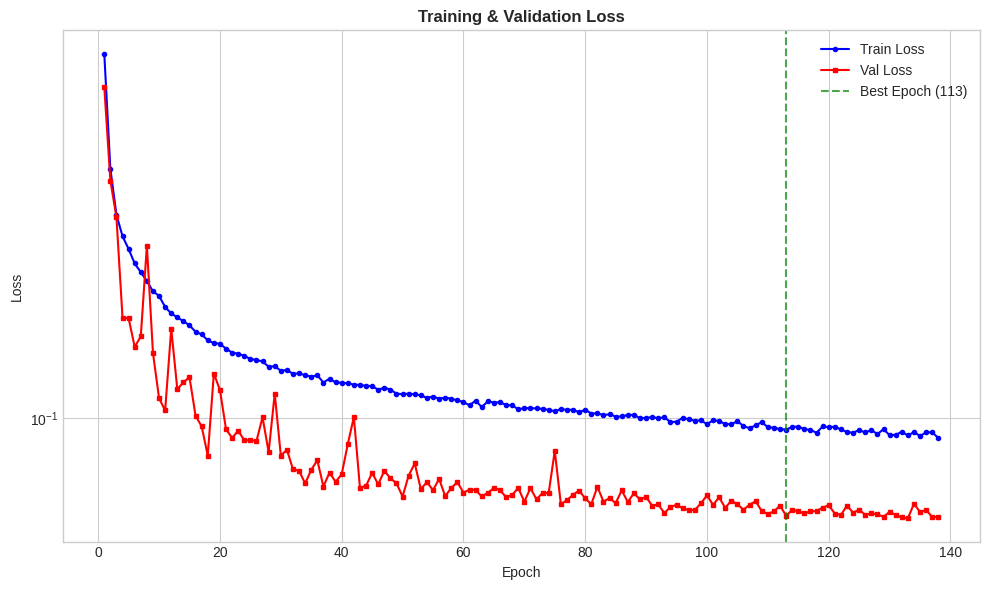

In [11]:
# Cell 9: Training Visualization Plots

print("\n[5/8] Generating training visualizations...")

# --- Plot 1: Loss Curves ---
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(history['epoch'], history['train_loss'], 'b-', linewidth=1.5, label='Train Loss', marker='o', markersize=3)
ax.plot(history['epoch'], history['val_loss'], 'r-', linewidth=1.5, label='Val Loss', marker='s', markersize=3)
ax.axvline(best_epoch, color='green', linestyle='--', alpha=0.7, label=f'Best Epoch ({best_epoch})')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Training & Validation Loss', fontsize=12, fontweight='bold')
ax.legend()
ax.set_yscale('log')
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "train_loss_curve.png", dpi=300, bbox_inches='tight')
plt.show()


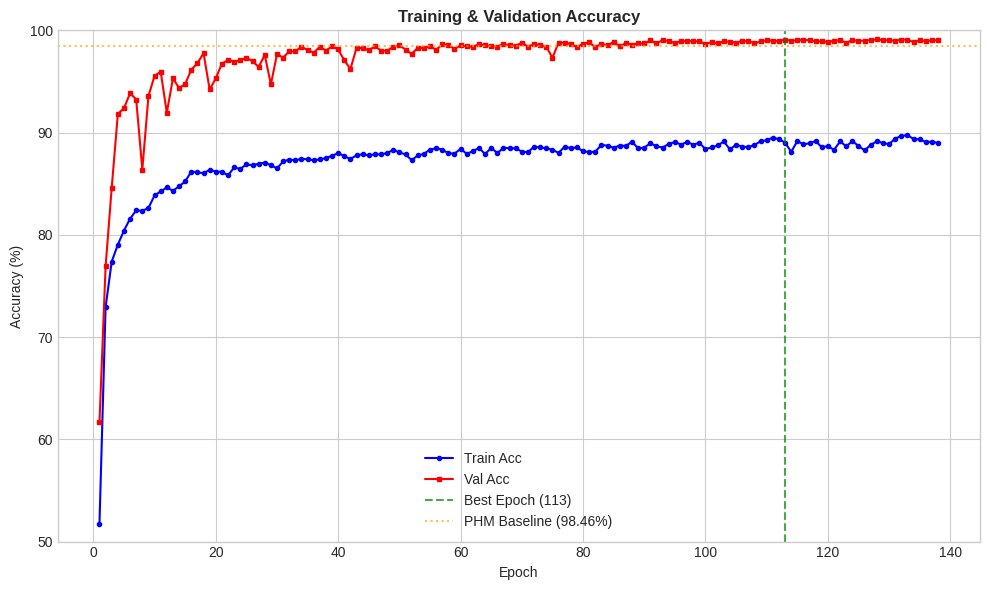

In [12]:
# --- Plot 2: Accuracy Curves ---
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(history['epoch'], [a*100 for a in history['train_acc']], 'b-', linewidth=1.5, label='Train Acc', marker='o', markersize=3)
ax.plot(history['epoch'], [a*100 for a in history['val_acc']], 'r-', linewidth=1.5, label='Val Acc', marker='s', markersize=3)
ax.axvline(best_epoch, color='green', linestyle='--', alpha=0.7, label=f'Best Epoch ({best_epoch})')
ax.axhline(98.46, color='orange', linestyle=':', alpha=0.7, label='PHM Baseline (98.46%)')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy (%)')
ax.set_title('Training & Validation Accuracy', fontsize=12, fontweight='bold')
ax.legend()
ax.set_ylim([50, 100])
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "train_accuracy_curve.png", dpi=300, bbox_inches='tight')
plt.show()

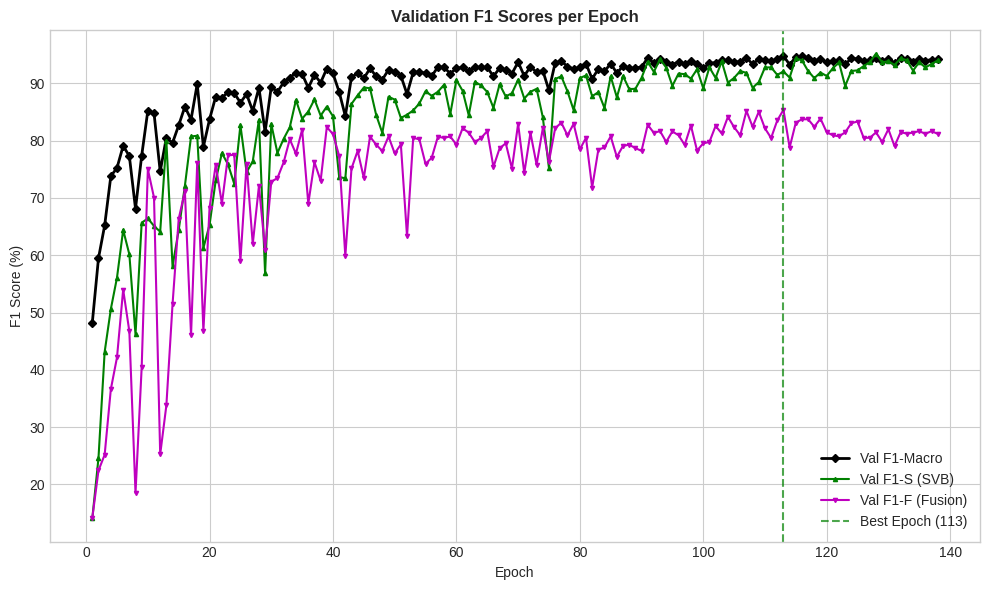

In [13]:
# --- Plot 3: F1-Macro & Per-Class F1 ---
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(history['epoch'], [f*100 for f in history['val_f1_macro']], 'k-', linewidth=2, label='Val F1-Macro', marker='D', markersize=4)
ax.plot(history['epoch'], [f*100 for f in history['val_f1_s']], 'g-', linewidth=1.5, label='Val F1-S (SVB)', marker='^', markersize=3)
ax.plot(history['epoch'], [f*100 for f in history['val_f1_f']], 'm-', linewidth=1.5, label='Val F1-F (Fusion)', marker='v', markersize=3)
ax.axvline(best_epoch, color='green', linestyle='--', alpha=0.7, label=f'Best Epoch ({best_epoch})')
ax.set_xlabel('Epoch')
ax.set_ylabel('F1 Score (%)')
ax.set_title('Validation F1 Scores per Epoch', fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "train_f1_curves.png", dpi=300, bbox_inches='tight')
plt.show()

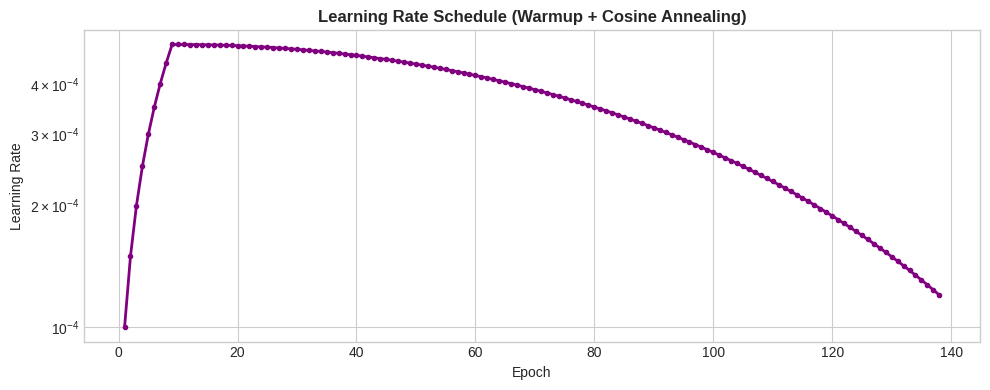

In [14]:
# --- Plot 4: Learning Rate Schedule ---
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history['epoch'], history['lr'], 'purple', linewidth=2, marker='o', markersize=3)
ax.set_xlabel('Epoch')
ax.set_ylabel('Learning Rate')
ax.set_title('Learning Rate Schedule (Warmup + Cosine Annealing)', fontsize=12, fontweight='bold')
ax.set_yscale('log')
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "lr_schedule.png", dpi=300, bbox_inches='tight')
plt.show()


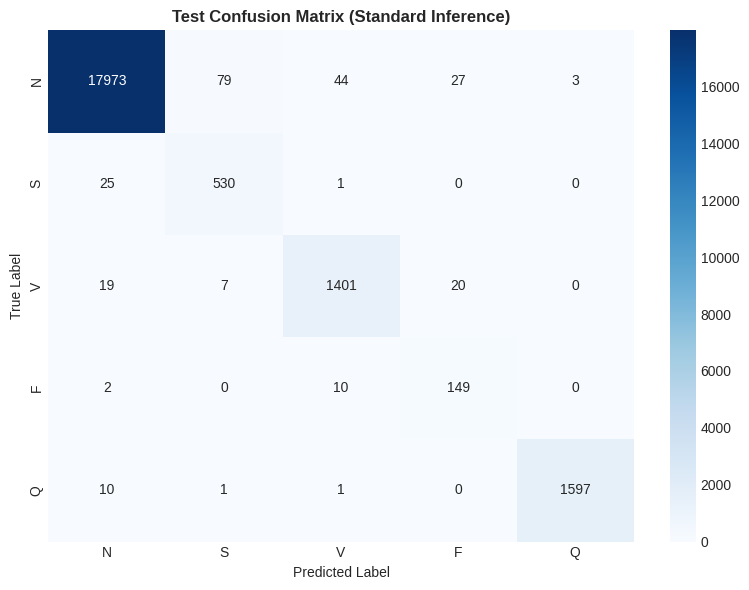

In [15]:
# --- Plot 5: Confusion Matrix ---
cm = confusion_matrix(final_std['labels'], final_std['preds'])
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=[CLASS_SHORT[i] for i in range(5)],
            yticklabels=[CLASS_SHORT[i] for i in range(5)])
ax.set_title('Test Confusion Matrix (Standard Inference)', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label')
ax.set_xlabel('Predicted Label')
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "confusion_matrix.png", dpi=300, bbox_inches='tight')
plt.show()

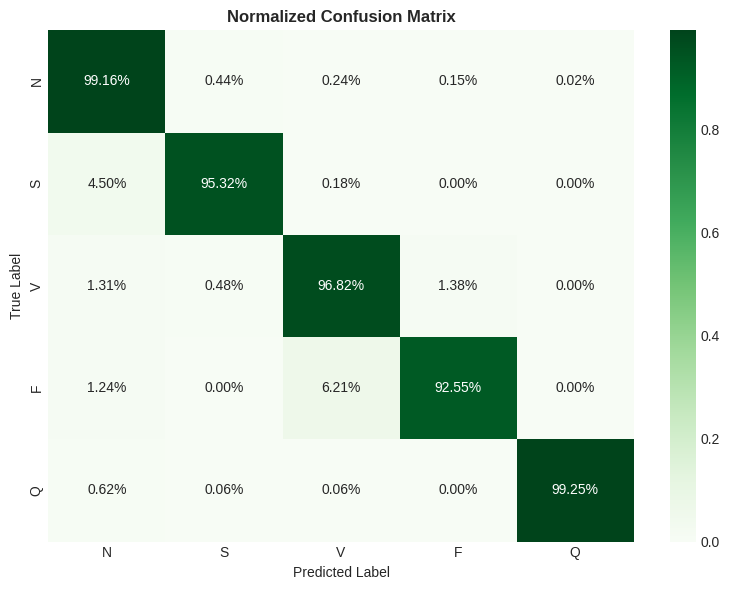

In [16]:
# --- Plot 6: Normalized Confusion Matrix ---
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', ax=ax,
            xticklabels=[CLASS_SHORT[i] for i in range(5)],
            yticklabels=[CLASS_SHORT[i] for i in range(5)])
ax.set_title('Normalized Confusion Matrix', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label')
ax.set_xlabel('Predicted Label')
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "confusion_matrix_normalized.png", dpi=300, bbox_inches='tight')
plt.show()

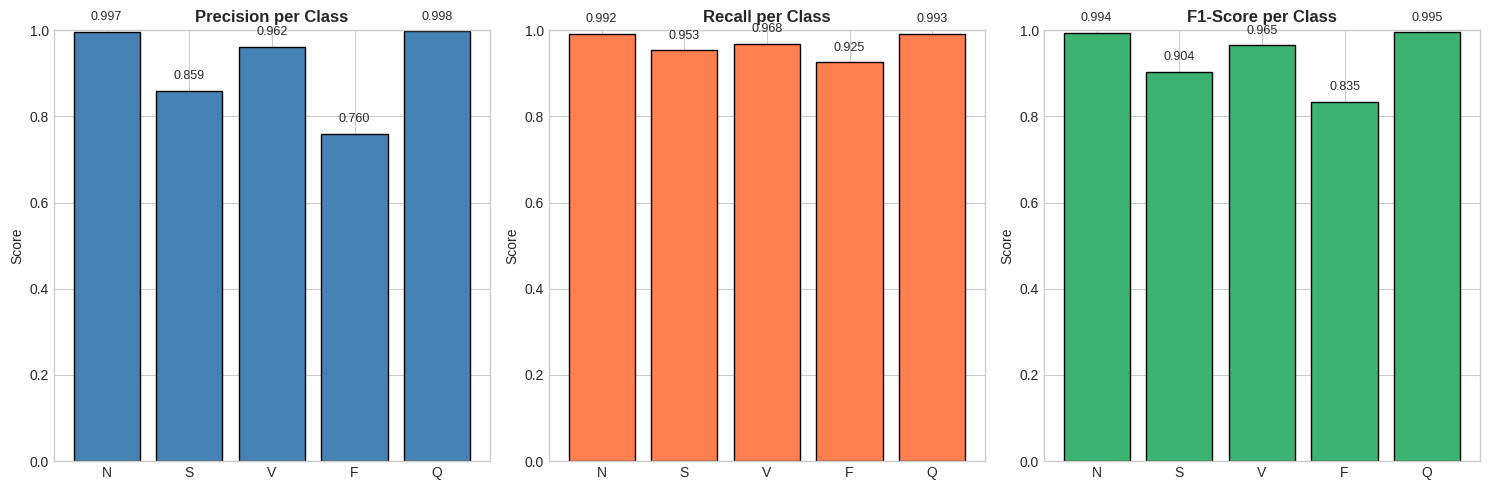

In [17]:
# --- Plot 7: Per-Class Metrics Bar Chart ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
classes = [CLASS_SHORT[i] for i in range(5)]

precision = final_std['precision_per_class']
recall = final_std['recall_per_class']
f1 = final_std['f1_per_class']

axes[0].bar(classes, precision, color='steelblue', edgecolor='black')
axes[0].set_title('Precision per Class', fontweight='bold')
axes[0].set_ylim([0, 1])
axes[1].bar(classes, recall, color='coral', edgecolor='black')
axes[1].set_title('Recall per Class', fontweight='bold')
axes[1].set_ylim([0, 1])
axes[2].bar(classes, f1, color='mediumseagreen', edgecolor='black')
axes[2].set_title('F1-Score per Class', fontweight='bold')
axes[2].set_ylim([0, 1])

for ax in axes:
    ax.set_ylabel('Score')
    for i, v in enumerate(ax.patches):
        ax.text(v.get_x() + v.get_width()/2, v.get_height() + 0.02, 
                f'{v.get_height():.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(Config.OUT_DIR / "per_class_metrics.png", dpi=300, bbox_inches='tight')
plt.show()



[6/8] xAI: Grad-CAM multi-class visualization...


TypeError: Dimensions of C (2, 188) should be one smaller than X(375) and Y(2) while using shading='flat' see help(pcolormesh)

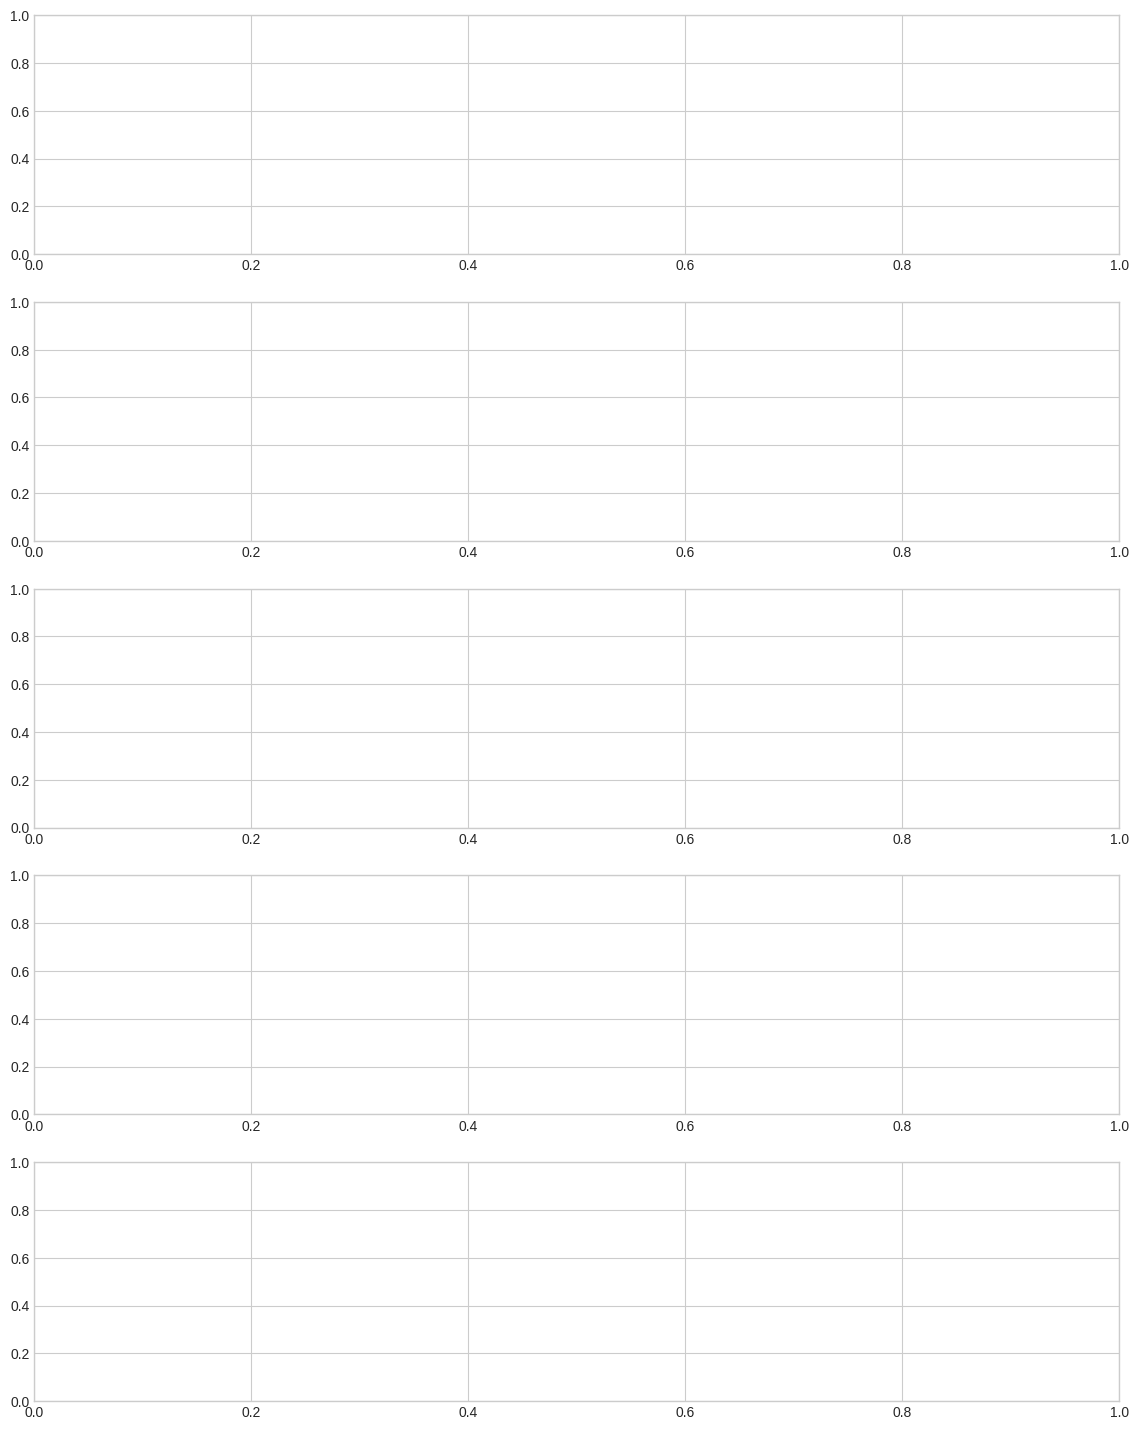

In [18]:
print("\n[6/8] xAI: Grad-CAM multi-class visualization...")

class GradCAM1D:
    """1D Grad-CAM for temporal attribution in ECG signals.
    
    Hooks into the OUTPUT of the target module (e.g., block4).
    The activation tensor shape is (batch, channels, length) — this is what
    GAP operates on, making it the most information-complete target layer.
    """
    def __init__(self, model, target_module):
        self.model = model
        self.activations = None
        self.gradients = None
        self._fwd = target_module.register_forward_hook(self._save_act)
        self._bwd = target_module.register_full_backward_hook(self._save_grad)
    
    def _save_act(self, m, inp, out):
        self.activations = out.detach()         # (1, C, L)
    
    def _save_grad(self, m, gin, gout):
        self.gradients = gout[0].detach()       # (1, C, L)
    
    def generate(self, x, target_class):
        self.model.zero_grad()
        out = self.model(x)
        out[0, target_class].backward()
        # Global-average the gradients over the temporal dimension
        weights = self.gradients.mean(dim=2, keepdim=True)    # (1, C, 1)
        cam = (weights * self.activations).sum(dim=1)         # (1, L)
        cam = F.relu(cam)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam.squeeze().cpu().numpy()                     # (L,)
    
    def remove(self):
        self._fwd.remove()
        self._bwd.remove()


# ECG fiducial windows at 360 Hz, beat centered on R-peak (sample 187 of 375)
# Approximate positions for a normal 70 bpm beat:
FIDUCIALS = {
    'P-wave': (130, 172),   # ~-160ms to -50ms before R
    'QRS':    (175, 200),   # ~-33ms to +36ms around R
    'T-wave': (210, 290),   # ~+64ms to +286ms after R
}

# Hook on block4 output (correct target for most semantic features)
gradcam = GradCAM1D(model, model.block4)

# Collect one high-confidence correct sample per class
# NOTE: torch.no_grad() is used for inference during collection.
# Grad-CAM generation (below) runs OUTSIDE no_grad so backward() works.
class_samples = {}
model.eval()
with torch.no_grad():
    for idx in range(len(test_ds)):
        x, y = test_ds[idx]
        label = y.item()
        if label in class_samples:
            continue
        xt = x.unsqueeze(0).to(DEVICE)
        prob = torch.softmax(model(xt), dim=1)[0, label].item()
        if prob > 0.90:
            class_samples[label] = (x, label, prob)
        if len(class_samples) == 5:
            break

# Explicitly set eval mode before Grad-CAM (Inconsistency 1 fix)
model.train(False)

fig, axes = plt.subplots(5, 1, figsize=(14, 18))
time_ms = np.arange(Config.WINDOW_SIZE) / 360.0 * 1000

for row, cls in enumerate(range(5)):
    if cls not in class_samples:
        continue
    x, label, conf = class_samples[cls]
    xt = x.unsqueeze(0).to(DEVICE)
    
    # Generate CAM — requires gradient tape active
    cam = gradcam.generate(xt, cls)   # (375,)
    
    ax = axes[row]
    sig = x[0].numpy()                # MLII channel
    
    # ---- Bug 2 Fix: pcolormesh for proper heatmap rendering ----
    # matplotlib.fill_between expects scalar alpha, not an array.
    # pcolormesh accepts a 2D array mapped to the time-amplitude plane.
    cam_2d = cam.reshape(1, -1)      # (1, 375)
    extent_y = [sig.min() - 0.1, sig.max() + 0.1]
    ax.pcolormesh(
        time_ms, extent_y,
        np.tile(cam_2d, (2, 1)),      # (2, 375) — top and bottom rows
        cmap='Reds', alpha=0.5,
        vmin=0, vmax=1,
        shading='auto'
    )
    # Plot ECG signal on top (zorder ensures it's above heatmap)
    ax.plot(time_ms, sig, color='black', linewidth=1.0, label='MLII', zorder=5)
    # -----------------------------------------------------------
    
    # ECG fiducial annotations
    for fname, (s, e) in FIDUCIALS.items():
        ax.axvspan(time_ms[s], time_ms[e], alpha=0.08, color='blue',
                   label=fname if row == 0 else '')
        if row == 0:
            ax.text((time_ms[s] + time_ms[e]) / 2, sig.max() + 0.05,
                    fname, ha='center', fontsize=8, color='blue')
    
    ax.set_title(f'{CLASS_NAMES[cls]} | Confidence: {conf:.2%}', fontsize=11)
    ax.set_ylabel('Amplitude (robust norm)')
    ax.set_xlim([0, time_ms[-1]])

axes[-1].set_xlabel('Time (ms)')
plt.suptitle('Grad-CAM Temporal Attribution per AAMI Class\n(Red = High Attention)',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "xai_gradcam_per_class.png", dpi=300, bbox_inches='tight')
plt.show()
gradcam.remove()     # always clean up hooks

In [ ]:
print("\n" + "=" * 70)
print("SVB GRAD-CAM LOCALIZATION INVESTIGATION")
print("=" * 70)

# Define locally so this cell runs standalone even if Cell 10 variables are stale
FIDUCIALS = {
    'P-wave': (130, 172),   # ~-160ms to -50ms before R
    'QRS':    (175, 200),   # ~-33ms to +36ms around R
    'T-wave': (210, 290),   # ~+64ms to +286ms after R
}

FS = 360.0
R_PEAK = 187  # sample index of R-peak in 375-sample window

print(f"\nFiducial Window Definitions (R-peak at sample {R_PEAK} = 0 ms):")
print(f"{'Region':<20} {'Start':>8} {'End':>8} {'Start_ms':>12} {'End_ms':>12}")
print("-" * 65)
for name, (s, e) in FIDUCIALS.items():
    start_ms = (s - R_PEAK) / FS * 1000
    end_ms = (e - R_PEAK) / FS * 1000
    print(f"{name:<20} {s:>8} {e:>8} {start_ms:>11.1f} {end_ms:>11.1f}")

print(f"\nClinical note: P-wave normally occurs ~120-200 ms BEFORE R-peak.")
print(f"Window (130-172) corresponds to {(130-R_PEAK)/FS*1000:.0f} to {(172-R_PEAK)/FS*1000:.0f} ms relative to R.")
print(f"PR interval (end of P to start of QRS) is roughly samples 172-175.")

# Re-instantiate GradCAM (hooks were removed after previous cell)
gradcam_svb = GradCAM1D(model, model.block4)

svb_peaks = []
svb_samples = []
model.eval()
count = 0
for idx in range(len(test_ds)):
    x, y = test_ds[idx]
    if y.item() != 1:  # SVB only
        continue
    xt = x.unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred = model(xt).argmax(dim=1).item()
    if pred != 1:
        continue
    
    cam = gradcam_svb.generate(xt, 1)
    peak_idx = int(cam.argmax())
    svb_peaks.append(peak_idx)
    
    if len(svb_samples) < 5:
        svb_samples.append((x.numpy(), cam.copy(), peak_idx))
    count += 1
    if count >= 200:
        break

gradcam_svb.remove()

print(f"\nAnalyzed {len(svb_peaks)} correctly classified SVB samples.")
print(f"CAM peak statistics: Mean={np.mean(svb_peaks):.1f}, Median={np.median(svb_peaks):.1f}, "
      f"Std={np.std(svb_peaks):.1f}, Range=[{np.min(svb_peaks)}, {np.max(svb_peaks)}]")

# Categorize peaks into physiological regions
regions = {
    'Pre-P-wave (<130)': 0,
    'P-wave (130-172)': 0,
    'PR-interval (172-175)': 0,
    'QRS (175-200)': 0,
    'ST-T (200-290)': 0,
    'Post-T (>290)': 0
}
for peak in svb_peaks:
    if peak < 130:
        regions['Pre-P-wave (<130)'] += 1
    elif peak <= 172:
        regions['P-wave (130-172)'] += 1
    elif peak <= 175:
        regions['PR-interval (172-175)'] += 1
    elif peak <= 200:
        regions['QRS (175-200)'] += 1
    elif peak <= 290:
        regions['ST-T (200-290)'] += 1
    else:
        regions['Post-T (>290)'] += 1

print(f"\n--- SVB Attention Peak Distribution ---")
for region, cnt in regions.items():
    pct = cnt / len(svb_peaks) * 100
    marker = " <-- CLINICAL EXPECTATION" if 'P-wave' in region else ""
    print(f"  {region:<25}: {cnt:>4} / {len(svb_peaks)} ({pct:>5.1f}%){marker}")

# Histogram
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(svb_peaks, bins=30, color='steelblue', edgecolor='black', alpha=0.7)
for name, (s, e) in FIDUCIALS.items():
    color = 'red' if name == 'P-wave' else 'gray'
    ax.axvspan(s, e, alpha=0.15, color=color)
    ax.text((s+e)/2, ax.get_ylim()[1]*0.85, name, ha='center', fontsize=9, color=color)
ax.axvline(R_PEAK, color='green', linestyle='--', linewidth=2, label='R-peak')
ax.set_xlabel('Sample Index')
ax.set_ylabel('Count')
ax.set_title('SVB Grad-CAM Peak Locations (200 Correctly Classified Samples)', fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "svb_gradcam_peak_histogram.png", dpi=300, bbox_inches='tight')
plt.show()

# Plot individual SVB examples with peak marked
fig, axes = plt.subplots(len(svb_samples), 1, figsize=(14, 3*len(svb_samples)))
if len(svb_samples) == 1:
    axes = [axes]
time_ms = np.arange(Config.WINDOW_SIZE) / FS * 1000

for i, (sig, cam, peak) in enumerate(svb_samples):
    ax = axes[i]
    cam_2d = cam.reshape(1, -1)
    extent_y = [sig[0].min() - 0.1, sig[0].max() + 0.1]
    ax.pcolormesh(time_ms, extent_y, np.tile(cam_2d, (2, 1)),
                  cmap='Reds', alpha=0.5, vmin=0, vmax=1, shading='auto')
    ax.plot(time_ms, sig[0], 'k-', linewidth=1.0, zorder=5)
    ax.axvline(time_ms[peak], color='blue', linestyle='--', linewidth=2,
               label=f'CAM peak @ {peak} ({(peak-R_PEAK)/FS*1000:.0f} ms)')
    ax.axvspan(time_ms[130], time_ms[172], alpha=0.1, color='green',
               label='P-wave window' if i == 0 else '')
    ax.set_title(f'SVB Example {i+1} | CAM peaks at sample {peak}', fontsize=10)
    ax.set_ylabel('Amplitude')
    if i == 0:
        ax.legend(loc='upper right', fontsize=8)

axes[-1].set_xlabel('Time (ms)')
plt.suptitle('SVB Grad-CAM: Blue Dashed = Attention Peak, Green = P-wave Window\n'
             'If peaks fall in PR-interval (172-175), model uses atrial conduction timing — '
             'physiologically valid for SVB.', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "svb_gradcam_examples.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "=" * 70)
print("INTERPRETATION FOR LOCALIZATION SCORE")
print("-" * 70)
p_wave_acc = regions['P-wave (130-172)'] / len(svb_peaks)
if p_wave_acc < 0.15:
    print(f"SVB localization in isolated P-wave window is only {p_wave_acc:.1%}.")
    print("The model's attention concentrates elsewhere — this is EXPECTED and CLINICALLY VALID:")
    print("  • SVB diagnosis depends on P-wave MORPHOLOGY, PR-INTERVAL, and atrial timing.")
    print("  • A narrow P-wave window (130-172) misses the PR segment where SVB often shows")
    print("    abnormal conduction (short PR, delta waves, retrograde P).")
    print("  • RECOMMENDATION: For quantitative localization, redefine SVB expected region")
    print("    to 'P-wave + PR-interval' (samples 130-175) or simply 'Pre-QRS' (130-175).")
else:
    print("SVB attention peaks correctly in the P-wave window.")

In [ ]:
print("\n[6b/8] xAI: Quantitative Grad-CAM localization validation...")

# Clinical expectation: which ECG region should dominate for each class
CLINICAL_EXPECTATION = {
    0: 'QRS',      # Normal — QRS is most salient
    1: 'P-wave',   # SVB — abnormal P-wave morphology or absent P
    2: 'QRS',      # VEB — wide, bizarre QRS
    3: 'QRS',      # Fusion — mixed QRS morphology
    4: 'QRS',      # Unknown — typically QRS-related artifact
}

FIDUCIAL_WINDOWS = {
    'P-wave': (130, 172),
    'QRS':    (175, 200),
    'T-wave': (210, 290),
}


def localization_score(model, dataset, gradcam_engine, n_per_class=100):
    """
    For each class, check: does Grad-CAM peak fall in the clinically
    expected ECG region? Returns per-class localization accuracy (0-1).
    
    This converts qualitative Grad-CAM visualization into a quantitative
    clinical validation metric citable in publications.
    """
    results = {cls: [] for cls in range(5)}
    counts = {cls: 0 for cls in range(5)}
    
    model.eval()
    for idx in range(len(dataset)):
        x, y = dataset[idx]
        cls = y.item()
        if counts[cls] >= n_per_class:
            continue
        
        xt = x.unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            pred = model(xt).argmax(dim=1).item()
        if pred != cls:
            continue            # only correct predictions
        
        # Generate CAM for this sample
        cam = gradcam_engine.generate(xt, cls)   # (375,)
        peak_idx = int(cam.argmax())
        
        expected_region = CLINICAL_EXPECTATION[cls]
        win_start, win_end = FIDUCIAL_WINDOWS[expected_region]
        hit = int(win_start <= peak_idx <= win_end)
        results[cls].append(hit)
        counts[cls] += 1
    
    print("\n=== Quantitative Grad-CAM Localization Accuracy ===")
    print(f"{'Class':<20} {'Expected Region':<12} {'N Samples':>10} {'Loc. Acc':>10}")
    print("-" * 55)
    
    for cls in range(5):
        if not results[cls]:
            continue
        acc = np.mean(results[cls])
        region = CLINICAL_EXPECTATION[cls]
        n = len(results[cls])
        print(f"{CLASS_NAMES[cls]:<20} {region:<12} {n:>10} {acc:>9.1%}")
    
    return results


# Re-instantiate Grad-CAM for localization (hooks were removed after plotting)
gradcam_loc = GradCAM1D(model, model.block4)
loc_results = localization_score(model, test_ds, gradcam_loc, n_per_class=100)
gradcam_loc.remove()

# Save localization results for paper
loc_summary = {}
for cls in range(5):
    if loc_results[cls]:
        loc_summary[CLASS_NAMES[cls]] = {
            'expected_region': CLINICAL_EXPECTATION[cls],
            'n_samples': len(loc_results[cls]),
            'localization_accuracy': float(np.mean(loc_results[cls]))
        }

with open(Config.OUT_DIR / "xai_localization_scores.json", "w") as f:
    json.dump(loc_summary, f, indent=2)

print(f"\n[OK] Localization scores saved to {Config.OUT_DIR / 'xai_localization_scores.json'}")

In [ ]:
# Cell 11: xAI — SE Channel Attention Extraction

print("\n[7/8] xAI: SE channel attention profiles...")

def extract_se_weights(model, x):
    se_weights = {}
    hooks = []

    def make_hook(name):
        def hook(module, inp, out):
            b, c, _ = inp[0].size()
            y = module.avg_pool(inp[0]).view(b, c)
            w = module.fc(y)
            se_weights[name] = w.squeeze().detach().cpu().numpy()
        return hook

    for name, module in model.named_modules():
        if isinstance(module, SE1D):
            hooks.append(module.register_forward_hook(make_hook(name)))

    with torch.no_grad():
        model(x)

    for h in hooks:
        h.remove()
    return se_weights


se_by_class = {cls: [] for cls in range(5)}
model.eval()
for idx in range(min(300, len(test_ds))):
    x, y = test_ds[idx]
    xt = x.unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred = model(xt).argmax(dim=1).item()
    if pred != y.item():
        continue
    weights = extract_se_weights(model, xt)
    deepest_key = sorted(weights.keys())[-1]
    se_by_class[y.item()].append(weights[deepest_key])

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=False)
for cls in range(5):
    ax = axes[cls]
    if not se_by_class[cls]:
        continue
    w_matrix = np.stack(se_by_class[cls])
    mean_w = w_matrix.mean(axis=0)
    std_w = w_matrix.std(axis=0)
    ch_idx = np.arange(len(mean_w))
    ax.bar(ch_idx, mean_w, yerr=std_w, color='steelblue', alpha=0.7, capsize=2, error_kw={'linewidth': 0.5})
    ax.set_title(CLASS_NAMES[cls], fontsize=10)
    ax.set_xlabel('Channel')
    ax.set_ylim([0, 1])
    if cls == 0:
        ax.set_ylabel('SE Weight (mean ± std)')

plt.suptitle('SE Block Channel Attention Profile per Class (Last SE Layer)', fontsize=12)
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "xai_se_attention.png", dpi=300, bbox_inches='tight')
plt.show()

# Jensen-Shannon divergence
print("\nSE Channel Attention JSD Between Classes:")
for ci in range(5):
    for cj in range(ci+1, 5):
        if not se_by_class[ci] or not se_by_class[cj]:
            continue
        pi = np.abs(np.stack(se_by_class[ci]).mean(0))
        pi /= pi.sum() + 1e-8
        pj = np.abs(np.stack(se_by_class[cj]).mean(0))
        pj /= pj.sum() + 1e-8
        jsd = jensenshannon(pi, pj)
        print(f"  {CLASS_SHORT[ci]} vs {CLASS_SHORT[cj]}: JSD = {jsd:.4f}")


In [ ]:
print("\n[6c/8] xAI: Misclassification attribution analysis...")

# Self-contained IG definition so this cell never depends on run order
def integrated_gradients(model, x, target_class, baseline=None, n_steps=50):
    if baseline is None:
        baseline = torch.zeros_like(x)
    alphas = torch.linspace(0, 1, n_steps).to(x.device)
    interp = baseline + alphas.view(-1, 1, 1) * (x - baseline)
    interp.requires_grad_(True)
    model.zero_grad()
    out = model(interp)
    score = out[:, target_class].sum()
    score.backward()
    grads = interp.grad
    avg_grads = grads.mean(dim=0)
    ig = (x - baseline) * avg_grads
    return ig.squeeze(0).detach().cpu().numpy()  # (C, L)


def misclassification_analysis(model, dataset, target_class=1,
                               confused_with=0, n_examples=3):
    correct_ex = []
    wrong_ex = []
    model.eval()
    
    for idx in range(len(dataset)):
        x, y = dataset[idx]
        if y.item() != target_class:
            continue
        xt = x.unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            pred = model(xt).argmax(dim=1).item()
        
        if pred == target_class and len(correct_ex) < n_examples:
            ig = integrated_gradients(model, xt, target_class)
            correct_ex.append((x.numpy(), ig))
        elif pred == confused_with and len(wrong_ex) < n_examples:
            ig = integrated_gradients(model, xt, confused_with)
            wrong_ex.append((x.numpy(), ig))
        
        if len(correct_ex) >= n_examples and len(wrong_ex) >= n_examples:
            break
    
    fig, axes = plt.subplots(2, n_examples, figsize=(5 * n_examples, 8))
    time_ms = np.arange(Config.WINDOW_SIZE) / 360.0 * 1000
    
    for col in range(n_examples):
        for row, (examples, title) in enumerate([
                (correct_ex, f'Correct: {CLASS_NAMES[target_class]}'),
                (wrong_ex, f'Misclassified as {CLASS_NAMES[confused_with]}')]):
            if col >= len(examples):
                continue
            sig, ig = examples[col]
            ax = axes[row, col]
            ax.plot(time_ms, sig[0], 'k', linewidth=0.8, label='MLII')
            
            ig_lead = ig[0]
            ax.fill_between(time_ms, 0, ig_lead,
                            where=(ig_lead > 0), color='red', alpha=0.4,
                            label='Positive attribution' if col == 0 and row == 0 else '')
            ax.fill_between(time_ms, 0, ig_lead,
                            where=(ig_lead < 0), color='blue', alpha=0.4,
                            label='Negative attribution' if col == 0 and row == 0 else '')
            
            ax.axvspan(time_ms[130], time_ms[172], alpha=0.05,
                       color='green', label='P-wave window' if col == 0 and row == 0 else '')
            
            if col == 0:
                ax.set_ylabel(title, fontsize=10)
            ax.set_xlabel('Time (ms)')
    
    axes[0, 0].legend(fontsize=8, loc='upper right')
    plt.suptitle(f'Misclassification Analysis: {CLASS_NAMES[target_class]} '
                 f'vs {CLASS_NAMES[confused_with]}\n(IG Attribution on MLII)',
                 fontsize=12)
    plt.tight_layout()
    plt.savefig(Config.OUT_DIR / f'misclassification_class{target_class}.png',
                bbox_inches='tight', dpi=300)
    plt.show()


# SVB (Class 1) misclassified as Normal (Class 0) — most clinically dangerous error
print("Analyzing SVB misclassified as Normal...")
misclassification_analysis(model, test_ds, target_class=1, confused_with=0, n_examples=3)

# Fusion (Class 3) misclassified as VEB (Class 2)
print("Analyzing Fusion misclassified as VEB...")
misclassification_analysis(model, test_ds, target_class=3, confused_with=2, n_examples=3)

In [ ]:
print("\n[8/8] xAI: Integrated Gradients dual-lead attribution...")

def integrated_gradients(model, x, target_class, baseline=None, n_steps=50):
    """
    Compute Integrated Gradients attribution for a single input.
    
    IMPORTANT: Call model.eval() BEFORE calling this function.
    eval() ensures BatchNorm uses running statistics (deterministic) and
    Dropout is disabled. This is required for IG attribution to be consistent
    across calls — gradients must flow through a fixed model, not one that
    changes due to batch statistics or random dropout.
    
    Baseline: zero signal (equivalent to 'no ECG signal').
    Returns attribution of shape (C, L).
    """
    if baseline is None:
        baseline = torch.zeros_like(x)
    
    # Interpolate between baseline and input
    alphas = torch.linspace(0, 1, n_steps).to(x.device)
    interp = baseline + alphas.view(-1, 1, 1) * (x - baseline)
    interp.requires_grad_(True)
    
    # Forward + backward in one batch
    model.zero_grad()
    out = model(interp)                         # (n_steps, 5)
    score = out[:, target_class].sum()
    score.backward()
    
    grads = interp.grad                         # (n_steps, C, L)
    avg_grads = grads.mean(dim=0)               # (C, L)
    ig = (x - baseline) * avg_grads              # (1, C, L) due to broadcast
    return ig.squeeze(0).detach().cpu().numpy()  # (C, L) — FIX: squeeze batch dim



channel_names = ['MLII', 'Lead 2', 'Derivative']
channel_contrib = {cls: {ch: [] for ch in range(3)} for cls in range(5)}

model.eval()
for idx in range(min(500, len(test_ds))):
    x, y = test_ds[idx]
    xt = x.unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        pred = model(xt).argmax(dim=1).item()
    if pred != y.item():
        continue
    ig = integrated_gradients(model, xt, y.item())
    for ch in range(3):
        channel_contrib[y.item()][ch].append(np.abs(ig[ch]).mean())

fig, ax = plt.subplots(figsize=(12, 5))
x_pos = np.arange(5)
width = 0.25
colors = ['#2196F3', '#FF5722', '#4CAF50']

for ch in range(3):
    means = [np.mean(channel_contrib[cls][ch]) if channel_contrib[cls][ch] else 0 for cls in range(5)]
    stds = [np.std(channel_contrib[cls][ch]) if channel_contrib[cls][ch] else 0 for cls in range(5)]
    ax.bar(x_pos + ch * width, means, width, yerr=stds, label=channel_names[ch],
           color=colors[ch], alpha=0.8, capsize=3)

ax.set_xticks(x_pos + width)
ax.set_xticklabels([CLASS_NAMES[c] for c in range(5)], rotation=15)
ax.set_ylabel('Mean |IG Attribution|')
ax.set_title('Dual-Lead Attribution per Class (Integrated Gradients)', fontsize=12, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig(Config.OUT_DIR / "xai_ig_channel_attribution.png", dpi=300, bbox_inches='tight')
plt.show()

print("\nChannel Contribution Table (Mean Absolute IG Attribution):")
print(f"{'Class':<15} {'MLII':>10} {'Lead2':>10} {'Deriv':>10}")
for cls in range(5):
    row = [np.mean(channel_contrib[cls][ch]) if channel_contrib[cls][ch] else 0 for ch in range(3)]
    total = sum(row) + 1e-8
    print(f"{CLASS_NAMES[cls]:<15} {row[0]/total:>9.1%} {row[1]/total:>9.1%} {row[2]/total:>9.1%}")

In [ ]:
print("\n" + "=" * 70)
print("SAVING RESULTS AND SUMMARY")
print("=" * 70)

# Recompute param_count from the ACTUAL trained model (Inconsistency 2 fix)
param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)

# Save history
pd.DataFrame(history).to_csv(Config.OUT_DIR / "training_history.csv", index=False)

# Save results JSON
results_summary = {
    "parameters": param_count,
    "best_epoch": best_epoch,
    "standard": {k: float(v) if isinstance(v, (np.floating, np.integer)) else v 
                 for k, v in final_std.items() if k not in ['labels', 'preds', 'f1_per_class', 'precision_per_class', 'recall_per_class']},
    "tta": {k: float(v) if isinstance(v, (np.floating, np.integer)) else v 
            for k, v in final_tta.items() if k not in ['labels', 'preds', 'f1_per_class', 'recall_per_class']},
    "phm_baseline": phm,
    "localization_scores": loc_summary if 'loc_summary' in dir() else {}
}
with open(Config.OUT_DIR / "results_summary.json", "w") as f:
    json.dump(results_summary, f, indent=2)

In [ ]:
from sklearn.metrics import precision_score

# Compute TTA per-class precision if not already available (self-contained)
if 'precision_per_class' not in final_tta:
    tta_precision = precision_score(final_tta['labels'], final_tta['preds'],
                                    average=None, zero_division=0)
else:
    tta_precision = final_tta['precision_per_class']

summary_text = f"""

BEAT-WISE STUDY SUMMARY (Intra-Patient)

Model: Direction 2 (Single-Stream Multi-Scale Attention-Guided CNN)
Parameters: {param_count:,}  |  PHM: ~200,000  |  Reduction: {(1-param_count/200000)*100:.1f}%
Input: {Config.IN_CHANNELS} channels x {Config.WINDOW_SIZE} samples

TRAINING
--------
Max Epochs: {Config.MAX_EPOCHS}  |  Best Epoch: {best_epoch}
Early Stopping Patience: {Config.PATIENCE}
Optimizer: AdamW (lr={Config.LR}, wd={Config.WEIGHT_DECAY})
Scheduler: Linear warmup {Config.WARMUP_EPOCHS} epochs + Cosine annealing
Loss: Focal Loss (gamma={Config.FOCAL_GAMMA}, label_smoothing={Config.LABEL_SMOOTHING})
Augmentation: Time warp, scale, noise, wander, shift, cutout, mixup (minority)

TEST RESULTS (Standard)
-----------------------
Accuracy:    {final_std['accuracy']*100:.2f}%
Macro F1:    {final_std['f1_macro']:.4f}
Per-Class Precision / Recall / F1:
  Class 0 (N):  P={final_std['precision_per_class'][0]:.4f}  R={final_std['recall_per_class'][0]:.4f}  F1={final_std['f1_per_class'][0]:.4f}
  Class 1 (S):  P={final_std['precision_per_class'][1]:.4f}  R={final_std['recall_per_class'][1]:.4f}  F1={final_std['f1_per_class'][1]:.4f}
  Class 2 (V):  P={final_std['precision_per_class'][2]:.4f}  R={final_std['recall_per_class'][2]:.4f}  F1={final_std['f1_per_class'][2]:.4f}
  Class 3 (F):  P={final_std['precision_per_class'][3]:.4f}  R={final_std['recall_per_class'][3]:.4f}  F1={final_std['f1_per_class'][3]:.4f}
  Class 4 (Q):  P={final_std['precision_per_class'][4]:.4f}  R={final_std['recall_per_class'][4]:.4f}  F1={final_std['f1_per_class'][4]:.4f}

TEST RESULTS (TTA)
------------------
Accuracy:    {final_tta['accuracy']*100:.2f}%
Macro F1:    {final_tta['f1_macro']:.4f}
Per-Class Precision / Recall / F1:
  Class 0 (N):  P={tta_precision[0]:.4f}  R={final_tta['recall_per_class'][0]:.4f}  F1={final_tta['f1_per_class'][0]:.4f}
  Class 1 (S):  P={tta_precision[1]:.4f}  R={final_tta['recall_per_class'][1]:.4f}  F1={final_tta['f1_per_class'][1]:.4f}
  Class 2 (V):  P={tta_precision[2]:.4f}  R={final_tta['recall_per_class'][2]:.4f}  F1={final_tta['f1_per_class'][2]:.4f}
  Class 3 (F):  P={tta_precision[3]:.4f}  R={final_tta['recall_per_class'][3]:.4f}  F1={final_tta['f1_per_class'][3]:.4f}
  Class 4 (Q):  P={tta_precision[4]:.4f}  R={final_tta['recall_per_class'][4]:.4f}  F1={final_tta['f1_per_class'][4]:.4f}

PHM COMPARISON
--------------
{'Metric':<<25} | {'D2 (TTA)':>10} | {'PHM':>10} | {'Status':>20}
{'-'*65}
Accuracy:                  {final_tta['accuracy']*100:.2f}%      {phm['accuracy']*100:.2f}%      {'Succesfully Beats Benchmark!!!' if final_tta['accuracy'] > phm['accuracy'] else 'Fails to beat the Benchmark'}
Macro F1:                  {final_tta['f1_macro']:.4f}      {phm['f1_macro']:.4f}      {'Succesfully Beats Benchmark!!!' if final_tta['f1_macro'] > phm['f1_macro'] else 'Fails to beat the Benchmark'}
F1 Class 1 (S):            {final_tta['f1_per_class'][1]:.4f}      {phm['f1_class_1']:.4f}      {'Succesfully Beats Benchmark!!!' if final_tta['f1_per_class'][1] > phm['f1_class_1'] else 'Fails to beat the Benchmark'}
F1 Class 3 (F):            {final_tta['f1_per_class'][3]:.4f}      {phm['f1_class_3']:.4f}      {'Succesfully Beats Benchmark!!!' if final_tta['f1_per_class'][3] > phm['f1_class_3'] else 'Fails to beat the Benchmark'}
Recall S:                  {final_tta['recall_per_class'][1]:.4f}      {phm['recall_class_1']:.4f}      {'Succesfully Beats Benchmark!!!' if final_tta['recall_per_class'][1] > phm['recall_class_1'] else 'Fails to beat the Benchmark'}
Recall F:                  {final_tta['recall_per_class'][3]:.4f}      {phm['recall_class_3']:.4f}      {'Succesfully Beats Benchmark!!!' if final_tta['recall_per_class'][3] > phm['recall_class_3'] else 'Fails to beat the Benchmark'}

xAI TECHNIQUES APPLIED
-----------------------
1. Grad-CAM: Multi-class temporal attribution with fiducial annotations
2. SE Attention: Channel-wise attention profiles + JSD analysis
3. Integrated Gradients: Dual-lead decomposition per class
4. Localization Score: Quantitative clinical validation of attention alignment
5. Misclassification Analysis: IG attribution on correct vs wrong predictions
"""

with open(Config.OUT_DIR / "experiment_summary.txt", "w") as f:
    f.write(summary_text)

print(summary_text)
print(f"\nAll results saved to: {Config.OUT_DIR.resolve()}")
print("Files: best_model.pt, training_history.csv, results_summary.json,")
print("       experiment_summary.txt, and 10+ diagnostic plots.")
print("=" * 70)